# Initialization

In [1]:
import xarray as xr
# import matplotlib as plt
from matplotlib import pyplot as plt
import pandas as pd
import geopandas as gpd
from math import sqrt
import seaborn as sns
import numpy as np


from sklearn import linear_model
from sklearn.model_selection import train_test_split
from sklearn.linear_model import BayesianRidge
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import mean_squared_error, r2_score 
from sklearn.preprocessing import StandardScaler

import warnings
warnings.filterwarnings('ignore')


#Choose whether to save plots
save_plots = False

# Change the matplotlib dpi to increase or decrease output size in vscode
plt.rcParams['figure.dpi'] = 150 

# Change some of the default xarray settings
xr.set_options(keep_attrs=True, display_expand_data=False)

def rmse(x,y):
    out = sqrt(mean_squared_error(x,y))
    return out


# Data Load-In

In [2]:

season_map = {

    12: 'Winter',
    1: 'Winter',
    2: 'Winter',
    3: 'Spring',
    4: 'Spring',
    5: 'Spring',
    6: 'Summer',
    7: 'Summer',
    8: 'Summer',
    9: 'Fall',
    10: 'Fall',
    11: 'Fall',
}


datapath = "/home/nlring/Documents/01_Research/larc-chicago-haq/datasets/"

fulldat = pd.read_csv(datapath+"fulldat-unaggregated-pixelmask.csv")
fulldat['datetime'] = pd.to_datetime(fulldat['datetime'], errors='coerce')
fulldat['hour'] = fulldat['datetime'].dt.hour
fulldat['season'] = fulldat['month'].map(season_map)

hourly = pd.read_csv(datapath+"fulldat-hourly-timeseries.csv")
hourly['datetime'] = pd.to_datetime(hourly['datetime'], errors='coerce')
hourly['hour'] = hourly['datetime'].dt.hour

diurnal = pd.read_csv(datapath+"fulldat-diurnal-aggregation.csv")
weekly = pd.read_csv(datapath+"fulldat-weekly-aggregation.csv")
monthly_diurnal = pd.read_csv(datapath+"fulldat-monthly-diurnal-aggregation.csv")
seasonal_diurnal = pd.read_csv(datapath+"fulldat-seasonal-diurnal-aggregation.csv")
monthly = pd.read_csv(datapath+"fulldat-monthly-aggregation.csv")



In [25]:
hourly

,Unnamed: 0,datetime,latitude,longitude,col_no2_mean,col_no2_median,col_no2_var,col_no2_sd,sfc_no2_mean,sfc_no2_median,...,solar_zenith_median,windspeed_2m_mean,windspeed_2m_median,winddir_2m_mean,winddir_2m_median,windspeed_10m_mean,windspeed_10m_median,winddir_10m_mean,winddir_10m_median,hour
0,0,2025-09-01,41.65,-87.61,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
1,1,2025-09-01,41.65,-87.57,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
2,2,2025-09-01,41.65,-87.55,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
3,3,2025-09-01,41.65,-87.53,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
4,4,2025-09-01,41.67,-87.67,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9926100,9926100,2026-06-15,42.01,-87.81,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
9926101,9926101,2026-06-15,42.01,-87.79,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
9926102,9926102,2026-06-15,42.01,-87.77,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
9926103,9926103,2026-06-15,42.01,-87.71,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0


# Preprocess Data
Train/test split and standardize

In [ ]:
var_select = ['sfc_no2_mean','col_no2_mean','pbl_mean', 'solar_zenith_mean', 'u2m_mean', 'v2m_mean']
target_col = 'sfc_no2_mean'
feature_cols = ['col_no2_mean', 'pbl_mean', 'solar_zenith_mean', 'u2m_mean', 'v2m_mean']

model_frame = hourly[var_select].dropna().copy()

train_df, test_df = train_test_split(model_frame, test_size=0.2, random_state=1219)

scaler_x = StandardScaler().fit(train_df[feature_cols])
scaler_y = StandardScaler().fit(train_df[[target_col]])

x_train = pd.DataFrame(scaler_x.transform(train_df[feature_cols]), columns=feature_cols, index=train_df.index)
x_test = pd.DataFrame(scaler_x.transform(test_df[feature_cols]), columns=feature_cols, index=test_df.index)

y_train = pd.Series(scaler_y.transform(train_df[[target_col]]).ravel(), name=target_col, index=train_df.index)
y_test = pd.Series(scaler_y.transform(test_df[[target_col]]).ravel(), name=target_col, index=test_df.index)


print(f"Train rows: {len(train_df)}, Test rows: {len(test_df)}")

model = linear_model.LinearRegression().fit(X=x_train, y=y_train)

train_score = r2_score(y_train, model.predict(x_train))
test_score = r2_score(y_test, model.predict(x_test))

print(f"\nTrain R2: {train_score:.3f}")
print(f"Test R2: {test_score:.3f}")

coef = np.ravel(model.coef_)
intercept = float(model.intercept_)

print("Coef: ", coef)
print("Intercept: ", intercept)


def estimate_no2(col_no2, pbl, sza, ws, wd):
    return intercept + coef[0] * col_no2 + coef[1] * pbl + coef[2] * sza + coef[3] * ws + coef[4] * wd

x_train_est = x_train.copy()
x_train_est['no2_estimate'] = x_train_est.apply(
    lambda row: estimate_no2(
        row.col_no2_mean,
        row.pbl_mean,
        row.solar_zenith_mean,
        row.u2m_mean,
        row.v2m_mean,
    ),
    axis=1,
)

# Convert the scaled prediction back to the original NO2 units.
x_train_est['no2_estimate_unscaled'] = scaler_y.inverse_transform(x_train_est[['no2_estimate']]).ravel()


x_test_est = x_test.copy()
x_test_est['no2_estimate'] = x_test_est.apply(
    lambda row: estimate_no2(
        row.col_no2_mean,
        row.pbl_mean,
        row.solar_zenith_mean,
        row.u2m_mean,
        row.v2m_mean,
    ),
    axis=1,
)

# Convert the scaled prediction back to the original NO2 units.
x_test_est['no2_estimate_unscaled'] = scaler_y.inverse_transform(x_test_est[['no2_estimate']]).ravel()



Train rows: 114492, Test rows: 28624

Train R2: 0.268
Test R2: 0.272
Coef:  [ 0.20505165 -0.31527209  0.17589521  0.08925574  0.18192242]
Intercept:  -7.337858452514364e-17


In [12]:
hourly['sfc_no2_mean'].dropna().shape

(143233,)

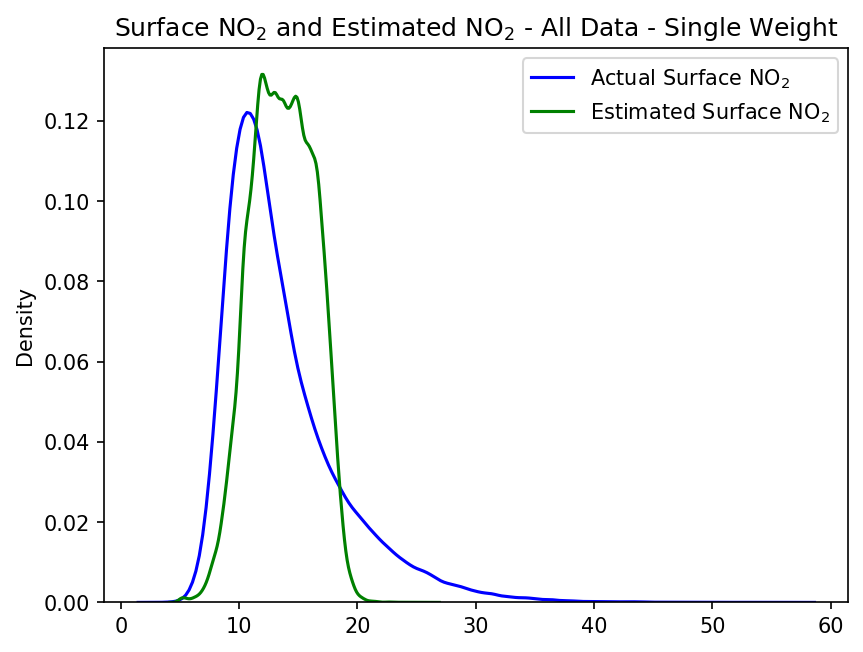

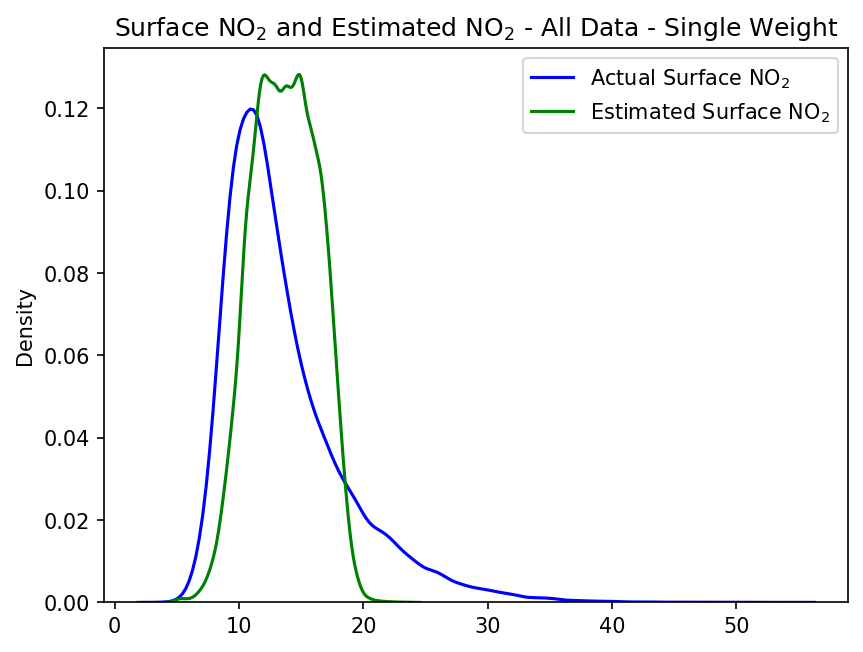

In [13]:
actual_surface = train_df['sfc_no2_mean'].to_numpy()
estimated_surface = x_train_est['no2_estimate_unscaled'].to_numpy()
actual_surface_test = test_df['sfc_no2_mean'].to_numpy()
estimated_surface_test = x_test_est['no2_estimate_unscaled'].to_numpy()


sns.kdeplot(actual_surface, color='blue', label='Actual Surface NO$_2$')
sns.kdeplot(estimated_surface, color='green', label='Estimated Surface NO$_2$')
plt.title("Surface NO$_2$ and Estimated NO$_2$ - All Data - Single Weight")
plt.legend()
# savefig("kde-actual-and-estimated-single-weight.png")
plt.show()

sns.kdeplot(actual_surface_test, color='blue', label='Actual Surface NO$_2$')
sns.kdeplot(estimated_surface_test, color='green', label='Estimated Surface NO$_2$')
plt.title("Surface NO$_2$ and Estimated NO$_2$ - All Data - Single Weight")
plt.legend()
# savefig("kde-actual-and-estimated-single-weight.png")
plt.show()

# eqn_text = f"y = 

In [5]:
var_select = ['sfc_no2_mean','col_no2_mean','pbl_mean', 'solar_zenith_mean', 'u2m_mean', 'v2m_mean']
target_col = 'sfc_no2_mean'
feature_cols = ['col_no2_mean', 'pbl_mean', 'solar_zenith_mean', 'u2m_mean', 'v2m_mean']
meta_cols = ['datetime', 'latitude', 'longitude']

def estimate_no2_from_model(x):
    return (
        intercept
        + coef[0] * x['col_no2_mean']
        + coef[1] * x['pbl_mean']
        + coef[2] * x['solar_zenith_mean']
        + coef[3] * x['u2m_mean']
        + coef[4] * x['v2m_mean']
    )

month_results = []
monthly_estimates = []

for month in sorted(hourly['datetime'].dt.month.dropna().unique()):
    month_frame = hourly.loc[
        hourly['datetime'].dt.month == month,
        meta_cols + var_select
    ].dropna().copy()
    if len(month_frame) < 10:
        continue

    train_df, test_df = train_test_split(month_frame, test_size=0.2, random_state=1219)

    scaler_x = StandardScaler().fit(train_df[feature_cols])
    scaler_y = StandardScaler().fit(train_df[[target_col]])

    x_train = pd.DataFrame(scaler_x.transform(train_df[feature_cols]), columns=feature_cols, index=train_df.index)
    x_test = pd.DataFrame(scaler_x.transform(test_df[feature_cols]), columns=feature_cols, index=test_df.index)

    y_train = pd.Series(scaler_y.transform(train_df[[target_col]]).ravel(), name=target_col, index=train_df.index)
    y_test = pd.Series(scaler_y.transform(test_df[[target_col]]).ravel(), name=target_col, index=test_df.index)

    model = linear_model.LinearRegression().fit(X=x_train, y=y_train)

    intercept = float(model.intercept_)
    coef = np.ravel(model.coef_)

    train_est_scaled = x_train.apply(estimate_no2_from_model, axis=1)
    test_est_scaled = x_test.apply(estimate_no2_from_model, axis=1)

    train_estimates = scaler_y.inverse_transform(pd.DataFrame(train_est_scaled, columns=['no2_estimate'])).ravel()
    test_estimates = scaler_y.inverse_transform(pd.DataFrame(test_est_scaled, columns=['no2_estimate'])).ravel()

    train_est = train_df[meta_cols + ['sfc_no2_mean']].copy()
    train_est['no2_estimate'] = train_estimates
    train_est['month'] = month
    train_est['split'] = 'train'
    train_est['residual'] = train_est['sfc_no2_mean'] - train_est['no2_estimate']

    test_est = test_df[meta_cols + ['sfc_no2_mean']].copy()
    test_est['no2_estimate'] = test_estimates
    test_est['month'] = month
    test_est['split'] = 'test'
    test_est['residual'] = test_est['sfc_no2_mean'] - test_est['no2_estimate']

    monthly_estimates.append(pd.concat([train_est, test_est], axis=0))

    month_results.append({
        'month': month,
        'train_rows': len(train_df),
        'test_rows': len(test_df),
        'train_score': r2_score(y_train, model.predict(x_train)),
        'test_score': r2_score(y_test, model.predict(x_test)),
        'intercept': intercept,
        'coef_col_no2': float(coef[0]),
        'coef_pbl': float(coef[1]),
        'coef_sza': float(coef[2]),
        'coef_u2m': float(coef[3]),
        'coef_v2m': float(coef[4]),
    })

model_vals = pd.DataFrame(month_results)
print(model_vals)

monthly_estimates_df = pd.concat(monthly_estimates, axis=0, ignore_index=True)
print(monthly_estimates_df.head())
monthly_estimates_df

   month  train_rows  test_rows  train_score  test_score     intercept  \
0      1        3564        891     0.170520    0.162202  1.376370e-16   
1      2        8840       2211     0.373611    0.374194  1.324757e-16   
2      3       13362       3341     0.221185    0.248413  5.988094e-17   
3      4       11961       2991     0.349815    0.343167 -3.316585e-16   
4      5       19880       4971     0.306050    0.292633 -9.575465e-17   
5      6          61         16     0.456330    0.359872 -5.379685e-16   
6      9       24684       6171     0.312669    0.291169  2.903401e-16   
7     10       18185       4547     0.279790    0.278306  2.718024e-17   
8     11       10958       2740     0.436727    0.404133  9.858947e-17   
9     12        2993        749     0.178317    0.179773 -8.293589e-16   

   coef_col_no2  coef_pbl  coef_sza  coef_u2m  coef_v2m  
0      0.041323 -0.389914  0.234591  0.008585 -0.228562  
1      0.206458 -0.461794  0.143945 -0.065920  0.144911  
2      0.19

,datetime,latitude,longitude,sfc_no2_mean,no2_estimate,month,split,residual
0,2026-01-05 15:00:00,41.97,-87.65,19.197727,17.199460,1,train,1.998267
1,2026-01-13 18:00:00,41.71,-87.67,13.770000,14.015570,1,train,-0.245570
2,2026-01-05 16:00:00,41.79,-87.61,16.016667,16.475291,1,train,-0.458625
3,2026-01-05 17:00:00,41.69,-87.63,10.853333,15.147939,1,train,-4.294605
4,2026-01-06 16:00:00,41.95,-87.79,23.310000,16.214726,1,train,7.095274
...,...,...,...,...,...,...,...,...
143111,2025-12-18 14:00:00,41.67,-87.63,12.374000,12.135430,12,test,0.238570
143112,2025-12-23 14:00:00,41.89,-87.77,20.877500,22.668610,12,test,-1.791110
143113,2025-12-17 14:00:00,41.87,-87.63,34.287500,19.916291,12,test,14.371209
143114,2025-12-23 15:00:00,41.77,-87.75,13.626667,21.249579,12,test,-7.622913


In [ ]:
vals = diurnal[['hour','latitude','longitude',
                'sfc_no2_mean','col_no2_mean','pbl_mean',
                'windspeed_2m_mean','winddir_2m_mean',
                'windspeed_10m_mean','winddir_10m_mean']].dropna()

model_rows = []
for hour in sorted(vals['hour'].dropna().unique()):
    x_hour = vals.loc[vals['hour'] == hour, ['col_no2_mean', 'pbl_mean','windspeed_2m_mean']]

    y_hour = vals.loc[vals['hour'] == hour, ['sfc_no2_mean']]

    hour_model = linear_model.LinearRegression().fit(X=x_hour, y=y_hour)
    model_rows.append({
        'hour': hour,
        'no2_coef': float(hour_model.coef_.ravel()[0]),
        'pbl_coef': float(hour_model.coef_.ravel()[1]),
        'sza_coef': float(hour_model.coef_.ravel()[2]),
        'intercept': float(hour_model.intercept_.ravel()[0]),
        'score': hour_model.score(X=x_hour, y=y_hour)
    })







model_vals = pd.DataFrame(model_rows)
print(model_vals)

vals = vals.merge(model_vals, on="hour", how="outer")

,hour,latitude,longitude,sfc_no2_mean,col_no2_mean,pbl_mean,windspeed_2m_mean,winddir_2m_mean,windspeed_10m_mean,winddir_10m_mean
0,0,41.65,-87.61,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0,41.65,-87.57,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0,41.65,-87.55,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0,41.65,-87.53,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0,41.67,-87.67,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
9926100,0,42.01,-87.81,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9926101,0,42.01,-87.79,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9926102,0,42.01,-87.77,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9926103,0,42.01,-87.71,NaN,NaN,NaN,NaN,NaN,NaN,NaN
